# Laboratorio 9. Series de tiempo y forecasting

## Notebook 3. Protocolo de validación y modelos propios

Este notebook cubre la función `backtest` y las métricas (sección 4), los modelos propios en PyTorch (MLP, DLinear, NLinear, LSTM y seq2seq), las iteraciones de hiperparámetros (5.2), la comparación de estrategias multi-paso (5.1), el modelo local contra el global (5.3), el reentrenamiento mensual y la sensibilidad a la semilla.

Todas las corridas están en `src/experimentos.py` y quedan guardadas en `Resultados/`. Si ya existen, el notebook solo las carga. Para entrenar todo desde cero basta con borrar `Resultados/iteraciones` y correr `python -m src.experimentos`.

In [1]:
import sys
import warnings
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
# pandas 2.3.3 con numpy 2.5 avisa al sumar Timedelta a Timestamp, es un aviso interno de pandas
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src import experimentos as E
from src.backtest import ORIGENES_VAL, SeasonalNaive, backtest
from src.data import cargar_panel
from src.registro import cargar_iteracion, cargar_metricas
from src.graficas import AZUL, NARANJA, VERDE, GRIS, GRIS_CLARO, CUALITATIVA, estilo, etiquetas_finales, guardar, pie

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
R = C.RESULTADOS

### 4. Protocolo de validación y métricas

Todos los modelos se evalúan con la misma función, `backtest(modelo)` en `src/backtest.py`. La usan los modelos propios de este notebook y los modelos de librería del notebook 4.

- El origen avanza 24 horas cada día. En prueba son 92 orígenes, del 2014-10-01 al 2014-12-31.
- En cada origen el modelo recibe solo la historia hasta las 23:00 del día anterior y devuelve las 24 horas siguientes. La función revisa en cada origen que la historia termine antes del origen y que el pronóstico tenga exactamente las 24 horas de cada cliente.
- Los pesos se entrenan una sola vez con datos hasta el 2014-09-30 (entrenamiento para los pesos y validación para el early stopping) y no se tocan durante los 92 orígenes.
- Un modelo es cualquier objeto con un método `predecir(historia, origen)` que devuelva `unique_id`, `ds` y `y_hat`, y si es probabilístico también `q10`, `q50` y `q90`.

Las métricas se calculan en kWh sobre todos los clientes y orígenes.

| Métrica | Cómo se calcula |
| --- | --- |
| MAE y RMSE | En kWh sobre todo el panel, y también por cliente |
| WAPE | Σ\|error\| / Σ\|real\| sobre todo el panel |
| MAPE | Promedio de \|error\| / \|real\|, dejando fuera las horas con consumo real igual a cero |
| MASE | Error absoluto de cada punto dividido entre el MAE del seasonal naive de 24 h de ese cliente en entrenamiento, y luego el promedio |

Un MASE de 1 quiere decir que el modelo se equivoca lo mismo que copiar el día anterior dentro de entrenamiento. Como cada error se divide entre la escala de su cliente, todos los clientes pesan lo mismo. En el WAPE y el MAE, en cambio, mandan los clientes grandes.

Para comprobar que el protocolo funciona se corre un seasonal naive hecho a mano sobre validación. El seasonal naive oficial, con StatsForecast, está en el notebook 4.

In [2]:
for m in (24, 168):
    r = backtest(SeasonalNaive(m), ORIGENES_VAL)
    print(f"seasonal naive {m:3d} h en validación   MAE {r['MAE']:.2f} kWh   WAPE {r['WAPE']:.4f}   "
          f"MASE {r['MASE']:.4f}   orígenes {r['n_origenes']}   inferencia {r['t_inferencia_s']:.1f} s")

seasonal naive  24 h en validación   MAE 41.22 kWh   WAPE 0.0639   MASE 0.9662   orígenes 92   inferencia 1.4 s


seasonal naive 168 h en validación   MAE 47.80 kWh   WAPE 0.0741   MASE 1.1521   orígenes 92   inferencia 1.4 s


### 5. Modelos propios

Todos los modelos reciben la ventana de las últimas L horas de un cliente, ya normalizada con su z-score de entrenamiento, y devuelven las 24 horas siguientes en esa misma escala. Luego se deshace la normalización para medir en kWh. Son modelos globales, o sea un solo modelo para los 100 clientes.

| Modelo | Qué hace | Covariables |
| --- | --- | --- |
| MLP | Aplana la ventana y el calendario de las 24 horas futuras y pasa por capas densas que sacan los 24 pasos juntos | Sí |
| DLinear | Separa la ventana en tendencia (media móvil de 25 horas) y resto, y a cada parte le aplica una capa lineal de L a 24 | No |
| NLinear | Le resta a la ventana su último valor, aplica una capa lineal de L a 24 y vuelve a sumar ese valor | No |
| LSTM multi-salida | Lee la ventana con la serie y el calendario, y una capa densa con el último estado oculto y el calendario futuro saca los 24 pasos | Sí |
| LSTM autorregresiva | Predice una hora, la usa como entrada para la siguiente y repite 24 veces | Sí |
| Seq2seq | Un encoder LSTM resume la ventana y un decoder LSTM genera las 24 horas, recibiendo en cada paso el calendario de esa hora | Sí |

El entrenamiento es igual para todos (`src/entrenamiento.py`). Se usa AdamW, pérdida L1 en la escala normalizada y recorte de gradiente en 1. En cada epoch se muestrean ventanas al azar solo del bloque de entrenamiento, 200 mil para los lineales y el MLP y 100 mil para los recurrentes, que por cada ventana tardan entre 45 y 180 veces más que DLinear según el estado oculto y la estrategia. Al final de cada epoch se mide la pérdida, el MAE y el MASE en validación con los 92 orígenes diarios, y el early stopping se queda con los pesos del mejor epoch de validación.

### 5.2 Iteraciones de hiperparámetros

Cada familia tiene una configuración base (L = 168, 30 meses de historia, z-score por serie) y en cada iteración se cambia un solo hiperparámetro. Hay iteraciones de la ventana L (48, 168 y 336 horas), de la historia de entrenamiento (3, 12 y 30 meses, siempre terminando el 2014-06-30), de la normalización (por serie, global y RevIN), del tamaño del estado oculto, del número de capas, del dropout, del learning rate y del tamaño de batch. La selección usa solo el MASE de validación.

In [3]:
tabla = E.tabla_iteraciones()
tabla = tabla[~tabla.id.str.contains("_seed|_H168")]
cols = ["id", "modelo", "L", "H", "meses", "norm", "oculto", "capas", "dropout", "lr", "batch", "tf",
        "epochs", "mejor_epoch", "params", "entrenables", "t_epoch_s", "t_total_s", "t_inferencia_s", "mem_mb",
        "perdida_train_final", "MAE_val", "MASE_val"]
t = tabla[cols].copy()
t["tf"] = np.where(t.modelo == "seq2seq", t.tf, np.nan)
t = t.sort_values(["modelo", "MASE_val"])
t.round({"t_epoch_s": 2, "t_total_s": 1, "t_inferencia_s": 1, "mem_mb": 0, "perdida_train_final": 4, "MAE_val": 2, "MASE_val": 4})

,id,modelo,L,H,meses,norm,oculto,capas,dropout,lr,batch,tf,epochs,mejor_epoch,params,entrenables,t_epoch_s,t_total_s,t_inferencia_s,mem_mb,perdida_train_final,MAE_val,MASE_val
3,dl_L336_revin,dlinear,336,24,30,revin,128,2,0.1,0.0010,1024,NaN,14,10,16178,16178,1.25,17.5,4.8,1041.0,0.2004,35.40,0.8348
9,dl_hist12,dlinear,336,24,12,revin,128,2,0.1,0.0010,1024,NaN,20,16,16178,16178,1.22,24.4,4.8,1066.0,0.2023,35.49,0.8377
10,dl_hist3,dlinear,336,24,3,revin,128,2,0.1,0.0010,1024,NaN,18,14,16178,16178,1.12,20.2,4.7,1340.0,0.2348,35.64,0.8396
2,dl_L336,dlinear,336,24,30,serie,128,2,0.1,0.0010,1024,NaN,11,7,16176,16176,0.25,2.7,4.8,1041.0,0.2014,35.67,0.8404
7,dl_h12,dlinear,168,24,12,serie,128,2,0.1,0.0010,1024,NaN,17,13,8112,8112,0.19,3.3,4.7,1041.0,0.2115,36.61,0.8524
5,dl_base,dlinear,168,24,30,serie,128,2,0.1,0.0010,1024,NaN,12,8,8112,8112,0.20,2.4,4.7,1041.0,0.2078,36.66,0.8528
11,dl_revin,dlinear,168,24,30,revin,128,2,0.1,0.0010,1024,NaN,13,9,8114,8114,1.10,14.4,4.5,1041.0,0.2075,36.64,0.8533
8,dl_h3,dlinear,168,24,3,serie,128,2,0.1,0.0010,1024,NaN,11,7,8112,8112,0.19,2.1,4.7,1041.0,0.2430,37.14,0.8586
4,dl_L48,dlinear,48,24,30,serie,128,2,0.1,0.0010,1024,NaN,18,14,2352,2352,0.16,2.8,4.5,1041.0,0.2330,39.92,0.9200
6,dl_global,dlinear,168,24,30,global,128,2,0.1,0.0010,1024,NaN,12,8,8112,8112,0.19,2.3,4.7,1041.0,0.0258,37.60,1.0072


En la tabla, `params` y `entrenables` son los parámetros totales y entrenables (todos los parámetros de estos modelos se entrenan), `t_epoch_s` es el tiempo promedio por epoch, `t_total_s` el tiempo total con early stopping, `t_inferencia_s` el tiempo de `backtest` sobre los 92 orígenes de validación y `mem_mb` la memoria pico que reporta el driver de MPS. La inferencia se mide en validación para que la prueba se use una sola vez por modelo. Casi todo ese tiempo es armar las ventanas con pandas en cada origen. Los lineales y el MLP tardan unos 4.6 s en total y las recurrentes entre 5.3 y 6.3 s, o sea la red recurrente agrega cerca de 1 a 1.5 s en los 92 orígenes.

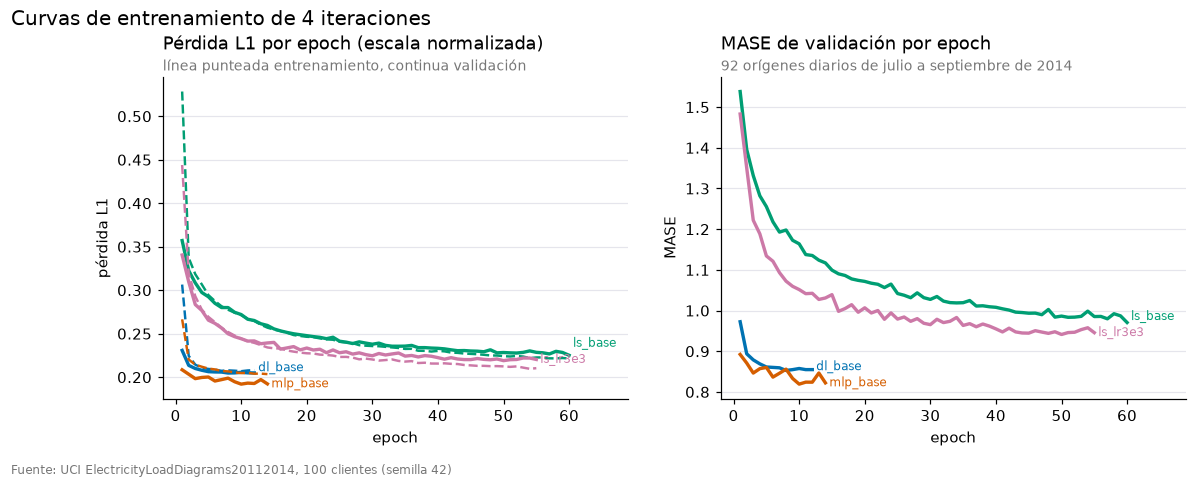

In [4]:
def curvas(ids, nombre, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    hs = [cargar_iteracion(i)["historial"] for i in ids]
    colores = CUALITATIVA[:len(ids)]
    for h, color in zip(hs, colores):
        axes[0].plot(h["epoch"], h["perdida_train"], color=color, lw=1.6, ls="--")
        axes[0].plot(h["epoch"], h["perdida_val"], color=color, lw=2.2)
        axes[1].plot(h["epoch"], h["mase_val"], color=color, lw=2.2)
    estilo(axes[0], "Pérdida L1 por epoch (escala normalizada)", "línea punteada entrenamiento, continua validación",
           "epoch", "pérdida L1")
    estilo(axes[1], "MASE de validación por epoch", "92 orígenes diarios de julio a septiembre de 2014", "epoch", "MASE")
    for ax, clave in zip(axes, ["perdida_val", "mase_val"]):
        ax.set_xlim(right=ax.get_xlim()[1] + 6)
        etiquetas_finales(ax, [h["epoch"][-1] + 0.6 for h in hs], [h[clave][-1] for h in hs], ids, colores)
    fig.suptitle(titulo, x=0.01, ha="left", y=1.04, fontsize=13)
    pie(fig)
    guardar(fig, nombre)
    plt.show()

curvas(["dl_base", "mlp_base", "ls_base", "ls_lr3e3"], "3_curvas_familias", "Curvas de entrenamiento de 4 iteraciones")

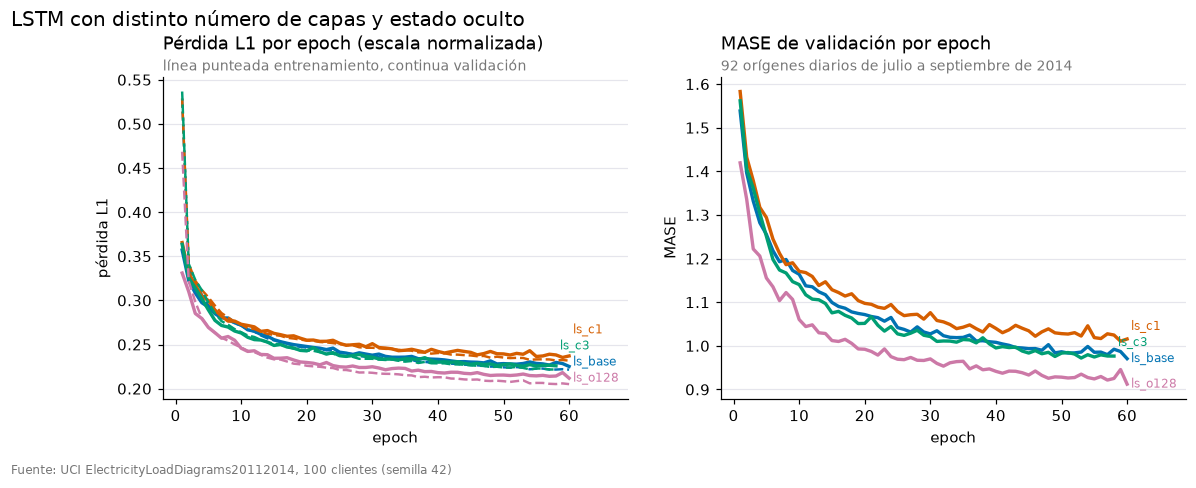

In [5]:
curvas(["ls_base", "ls_c1", "ls_c3", "ls_o128"], "3_curvas_lstm", "LSTM con distinto número de capas y estado oculto")

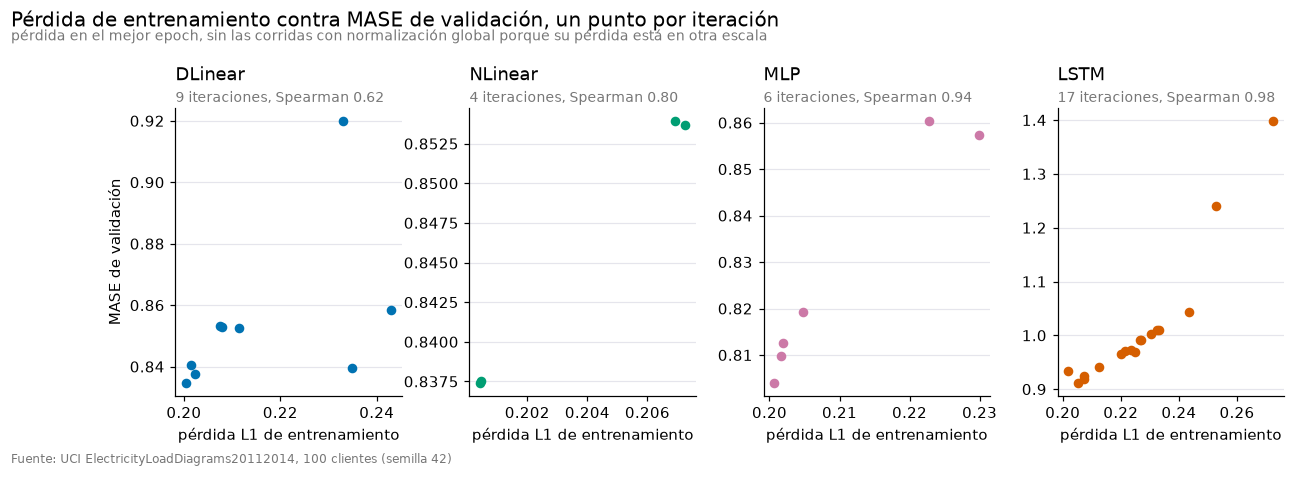

Correlación de Spearman entre pérdida de entrenamiento y MASE de validación
familia              iteraciones  n  Spearman
DLinear sin normalización global  9      0.62
DLinear                    todas 10      0.18
NLinear sin normalización global  4      0.80
NLinear                    todas  4      0.80
    MLP sin normalización global  6      0.94
    MLP                    todas  6      0.94
   LSTM sin normalización global 17      0.98
   LSTM                    todas 18      0.66


In [6]:
# ¿Una pérdida de entrenamiento más baja implica siempre un mejor MASE en validación?
# Con normalización global la pérdida se mide en otra escala (todas las series con la misma media
# y desviación), así que esas corridas se dejan fuera de la gráfica
familias = {"dlinear": ("DLinear", AZUL), "nlinear": ("NLinear", VERDE), "mlp": ("MLP", "#CC79A7"),
            "lstm": ("LSTM", NARANJA)}
iters = tabla[tabla.H == C.H]
comparables = iters[iters.norm != "global"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (m, (nombre, color)) in zip(axes, familias.items()):
    sub = comparables[comparables.modelo == m]
    rho = sub.perdida_train_final.rank().corr(sub.MASE_val.rank())
    ax.scatter(sub.perdida_train_final, sub.MASE_val, color=color, s=28)
    estilo(ax, nombre, f"{len(sub)} iteraciones, Spearman {rho:.2f}", "pérdida L1 de entrenamiento",
           "MASE de validación" if m == "dlinear" else None)
fig.suptitle("Pérdida de entrenamiento contra MASE de validación, un punto por iteración", x=0.01, ha="left",
             y=1.14, fontsize=13)
fig.text(0.01, 1.06, "pérdida en el mejor epoch, sin las corridas con normalización global porque su pérdida está en otra escala",
         color="#777777", fontsize=9)
fig.subplots_adjust(wspace=0.3)
pie(fig)
guardar(fig, "3_perdida_vs_mase")
plt.show()

filas = []
for m, (nombre, _) in familias.items():
    for etiqueta, base in [("sin normalización global", comparables), ("todas", iters)]:
        sub = base[base.modelo == m]
        filas.append({"familia": nombre, "iteraciones": etiqueta, "n": len(sub),
                      "Spearman": sub.perdida_train_final.rank().corr(sub.MASE_val.rank())})
print("Correlación de Spearman entre pérdida de entrenamiento y MASE de validación")
print(pd.DataFrame(filas).round(2).to_string(index=False))

Una pérdida de entrenamiento más baja no garantiza un mejor MASE de validación. El caso más claro es la normalización global. DLinear y la LSTM con normalización global tienen la pérdida más baja de todas sus iteraciones (0.026 y 0.050) y a la vez el peor MASE (1.007 y 2.219). Con una sola media y una sola desviación para todo el panel, los clientes chicos quedan con valores casi en cero y la pérdida L1 la ponen los pocos clientes grandes. Pero el MASE pesa a todos los clientes por igual, entonces el modelo queda bien en la pérdida y mal en la métrica. Por eso esas corridas no salen en la gráfica y la correlación de Spearman baja mucho cuando se incluyen (de 0.62 a 0.18 en DLinear y de 0.98 a 0.66 en la LSTM).

Dentro de una misma normalización el orden sí se parece bastante. En la LSTM la correlación es 0.98 y en el MLP 0.94, o sea la iteración que mejor ajusta el entrenamiento casi siempre es la que mejor valida. En DLinear baja a 0.62 por dos razones. Las corridas con 3 y 12 meses de historia miden su pérdida sobre otros datos de entrenamiento, y con 3 meses la pérdida sube a 0.235 aunque el MASE sigue en 0.840. Además la iteración con L = 48 tiene una pérdida parecida a la de otras corridas pero valida mucho peor (0.920), porque con dos días de ventana no ve el ciclo semanal.

En las curvas de entrenamiento no se ve sobreajuste fuerte. La pérdida de validación queda cerca de la de entrenamiento y los lineales y el MLP se detienen solos entre los epochs 10 y 30. Pero varias LSTM, incluida la mejor (`ls_o128`), llegaron al tope de 60 epochs y seguían mejorando un poco, entonces con más epochs la LSTM podría bajar algo más su MASE.

In [7]:
# Efecto de la ventana L, la normalización y la historia, con el resto de la configuración base
def efecto(familia, ids, etiquetas):
    filas = []
    for i, e in zip(ids, etiquetas):
        info = cargar_iteracion(i)
        if info:
            filas.append({"familia": familia, "variante": e, "MASE_val": info["mase_val"], "MAE_val": info["mae_val"]})
    return filas

filas = []
filas += efecto("DLinear", ["dl_L48", "dl_base", "dl_L336"], ["L = 48", "L = 168", "L = 336"])
filas += efecto("MLP", ["mlp_base", "mlp_L336"], ["L = 168", "L = 336"])
filas += efecto("NLinear", ["nl_base", "nl_L336"], ["L = 168", "L = 336"])
filas += efecto("LSTM", ["ls_L48", "ls_base", "ls_L336"], ["L = 48", "L = 168", "L = 336"])
print("Ventana L")
print(pd.DataFrame(filas).round(4).to_string(index=False))

filas = []
filas += efecto("DLinear", ["dl_base", "dl_global", "dl_revin"], ["por serie", "global", "RevIN"])
filas += efecto("NLinear", ["nl_base", "nl_revin"], ["por serie", "RevIN"])
filas += efecto("MLP", ["mlp_base", "mlp_revin"], ["por serie", "RevIN"])
filas += efecto("LSTM", ["ls_base", "ls_global", "ls_revin"], ["por serie", "global", "RevIN"])
print("\nNormalización")
print(pd.DataFrame(filas).round(4).to_string(index=False))

Ventana L
familia variante  MASE_val  MAE_val
DLinear   L = 48    0.9200  39.9227
DLinear  L = 168    0.8528  36.6648
DLinear  L = 336    0.8404  35.6715
    MLP  L = 168    0.8192  35.1166
    MLP  L = 336    0.8097  34.2463
NLinear  L = 168    0.8539  36.6857
NLinear  L = 336    0.8375  35.4250
   LSTM   L = 48    1.0091  44.1543
   LSTM  L = 168    0.9706  42.4799
   LSTM  L = 336    0.9917  43.5120

Normalización
familia  variante  MASE_val  MAE_val
DLinear por serie    0.8528  36.6648
DLinear    global    1.0072  37.6009
DLinear     RevIN    0.8533  36.6376
NLinear por serie    0.8539  36.6857
NLinear     RevIN    0.8537  36.6906
    MLP por serie    0.8192  35.1166
    MLP     RevIN    0.8041  34.0802
   LSTM por serie    0.9706  42.4799
   LSTM    global    2.2185  73.3891
   LSTM     RevIN    0.9656  41.9675


La ventana de 336 horas (dos semanas) mejora un poco a los lineales y al MLP. DLinear baja de 0.853 a 0.840, NLinear de 0.854 a 0.838 y el MLP de 0.819 a 0.810. Con dos semanas el modelo ve dos veces el ciclo semanal y puede promediarlo. La ventana de 48 horas es claramente peor en DLinear (0.920) y en la LSTM (1.009), porque no alcanza a ver el mismo día de la semana anterior. La LSTM va mejor con 168 horas que con 336 (0.971 contra 0.992). Con 336 pasos el gradiente tiene que recorrer el doble de la secuencia y cada epoch tarda unas tres veces más, entonces dentro de los 60 epochs aprende menos.

La normalización global es la peor en las dos familias donde se probó (DLinear 1.007 y LSTM 2.219). Las escalas de los clientes van de 21 a 11,480 kWh por hora, unas 550 veces, y con una sola escala el modelo casi no distingue la forma de los clientes chicos. Entre el z-score por serie y RevIN la diferencia es pequeña en los lineales (DLinear 0.853 contra 0.853 y NLinear 0.854 contra 0.854). En el MLP RevIN sí ayuda (de 0.819 a 0.804) y en la LSTM un poco (de 0.971 a 0.966). RevIN se aplica encima del z-score por serie y vuelve a normalizar cada ventana con su propia media y desviación. Eso le sirve al modelo cuando el nivel de la serie cambia respecto al entrenamiento, como pasa en validación, que cae en el verano.

Al combinar los dos cambios que funcionaron, L = 336 con RevIN, DLinear y NLinear mejoraron un poco más (0.835 y 0.837). En el MLP la combinación no le ganó a RevIN solo (0.813 contra 0.804). Por eso la configuración final del MLP usa L = 168.

#### Historia de entrenamiento

Para DLinear y la mejor LSTM se entrenó con 3, 12 y 30 meses de historia, siempre terminando el 2014-06-30, y se midió el MASE en validación. Estos puntos son parte de la gráfica 3 de la comparación final (notebook 5), junto con el seasonal naive, LightGBM y PatchTST.

modelo  DLinear    LSTM
meses                  
3        0.8396  1.2406
12       0.8377  0.9330
30       0.8348  0.9122


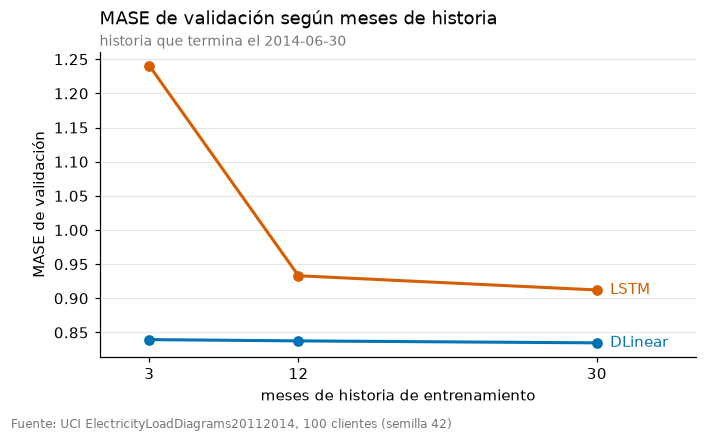

In [8]:
hist = pd.DataFrame([json.loads(p.read_text()) for p in sorted((R / "historia").glob("*.json"))])
hist = hist[hist.modelo.isin(["DLinear", "LSTM"])]
print(hist.pivot(index="meses", columns="modelo", values="MASE_val").round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 3.6))
for (m, g), color in zip(hist.groupby("modelo"), [AZUL, NARANJA]):
    g = g.sort_values("meses")
    ax.plot(g.meses, g.MASE_val, "o-", color=color, lw=2)
    ax.text(g.meses.iloc[-1] + 0.8, g.MASE_val.iloc[-1], m, color=color, va="center")
ax.set_xticks([3, 12, 30])
ax.set_xlim(0, 36)
estilo(ax, "MASE de validación según meses de historia", "historia que termina el 2014-06-30",
       "meses de historia de entrenamiento", "MASE de validación")
pie(fig)
guardar(fig, "3_historia_propios")
plt.show()

DLinear casi no cambia con la historia. Con 3 meses tiene MASE 0.840 y con 30 meses 0.835. Es un modelo lineal con unos 16 mil parámetros, y 3 meses de 100 clientes ya dan unas 200 mil ventanas, más que suficientes para estimarlo. La LSTM en cambio necesita mucha más historia. Con 3 meses llega a 1.241, peor que copiar el día anterior, y se detiene en el epoch 14 porque empieza a sobreajustar. Con 12 meses baja a 0.933 y con 30 meses a 0.912. Además los 3 meses de abril a junio no tienen ningún verano, y validación cae justo de julio a septiembre. Con 12 meses el modelo ya vio el verano de 2013. Entonces para la LSTM la historia larga ayuda por cantidad de datos y también porque incluye la misma época del año que se va a pronosticar.

### Configuraciones finales y resultados en prueba

De cada familia se toma la iteración con menor MASE de validación y solo esa se evalúa en prueba, una sola vez, con `backtest` sobre los 92 orígenes.

In [9]:
nombres = list(E.FINALES)
met = {n: cargar_metricas(n) for n in nombres}
filas = []
for n, m in met.items():
    c = m["config"]
    filas.append({"modelo": n, "familia": m["familia"], "iteración": m["id_iteracion"], "L": m["L"],
                  "estrategia": m["estrategia"], "covariables": m["covariables"],
                  "params": m["params_total"], "entrenables": m["params_entrenables"],
                  "t_entrenamiento_s": m["t_entrenamiento_s"], "t_inferencia_s": m["t_inferencia_s"],
                  "MAE": m["MAE"], "RMSE": m["RMSE"], "WAPE": m["WAPE"], "MAPE": m["MAPE"], "MASE": m["MASE"],
                  "MASE_h168": m.get("MASE_h168"), "MASE_navidad": m["MASE_navidad"], "MASE_val": m["MASE_val"]})
final = pd.DataFrame(filas).sort_values("MASE")
print("Hardware", met[nombres[0]]["hardware"])
final.round({"t_entrenamiento_s": 1, "t_inferencia_s": 1, "MAE": 2, "RMSE": 2, "WAPE": 4, "MAPE": 4,
             "MASE": 4, "MASE_h168": 4, "MASE_navidad": 4, "MASE_val": 4})

Hardware Apple M3 Max (MPS)


,modelo,familia,iteración,L,estrategia,covariables,params,entrenables,t_entrenamiento_s,t_inferencia_s,MAE,RMSE,WAPE,MAPE,MASE,MASE_h168,MASE_navidad,MASE_val
0,MLP,MLP y lineales,mlp_revin,168,multi-salida,True,447514,447514,6.0,5.0,37.37,183.28,0.0662,0.0845,0.8194,1.0009,1.4664,0.8041
1,DLinear,MLP y lineales,dl_L336_revin,336,multi-salida,False,16178,16178,17.5,5.3,37.88,185.61,0.0671,0.0935,0.8614,0.9872,1.8625,0.8348
2,NLinear,MLP y lineales,nl_L336_revin,336,multi-salida,False,8090,8090,6.4,5.1,37.79,184.87,0.0670,0.0936,0.8641,0.9854,1.8546,0.8374
5,Seq2seq,Encoder-decoder,s2s_tf0,168,encoder-decoder,True,405633,405633,1080.3,6.4,40.46,200.62,0.0717,0.0890,0.8657,NaN,1.3853,0.8876
3,LSTM,Recurrentes,ls_o128,168,multi-salida,True,243864,243864,940.8,6.3,42.03,192.54,0.0745,0.0948,0.8962,NaN,1.4144,0.9122
4,LSTM_AR,Recurrentes,ar_base,168,autorregresiva,True,202881,202881,839.2,6.4,42.47,196.59,0.0753,0.0952,0.9087,NaN,1.4273,0.9346


In [10]:
print("Configuración final de cada modelo")
cfgs = pd.DataFrame({n: m["config"] for n, m in met.items()}).T
# El teacher forcing solo lo usa el seq2seq
cfgs.loc[cfgs.modelo != "seq2seq", "teacher_forcing"] = np.nan
cfgs[["modelo", "L", "meses", "norm", "oculto", "capas", "dropout", "lr", "batch", "teacher_forcing", "muestras_epoch"]]

Configuración final de cada modelo


,modelo,L,meses,norm,oculto,capas,dropout,lr,batch,teacher_forcing,muestras_epoch
MLP,mlp,168,30,revin,512,2,0.1,0.001,1024,NaN,200000
DLinear,dlinear,336,30,revin,128,2,0.1,0.001,1024,NaN,200000
NLinear,nlinear,336,30,revin,128,2,0.1,0.001,1024,NaN,200000
LSTM,lstm,168,30,serie,128,2,0.1,0.001,1024,NaN,100000
LSTM_AR,lstm_ar,168,30,serie,128,2,0.1,0.001,1024,NaN,100000
Seq2seq,seq2seq,168,30,serie,128,2,0.1,0.001,1024,0.0,100000


El mejor modelo propio en prueba es el MLP con RevIN, con MASE 0.819, MAE de 37.4 kWh y WAPE de 6.6 %. El seasonal naive de 24 h tiene MASE 1.034 en el mismo bloque, entonces el MLP se equivoca cerca de 21 % menos. Le siguen DLinear (0.861), NLinear (0.864) y el seq2seq (0.866), casi empatados. Al final quedan la LSTM multi-salida (0.896) y la autorregresiva (0.909).

Lo más llamativo es el costo. DLinear y NLinear tienen 16 mil y 8 mil parámetros, se entrenan en 6 a 18 segundos y quedan a 0.04 del MLP. Las tres recurrentes tienen entre 200 mil y 400 mil parámetros, tardan entre 14 y 18 minutos y no les ganan a los lineales en el total. La inferencia de los 92 orígenes tarda entre 5 y 6.5 segundos en todos, o sea en producción el costo está en el entrenamiento. DLinear y NLinear tampoco usan el calendario, solo la ventana de consumo.

El orden de los 6 modelos en validación es exactamente el mismo que en prueba, entonces la selección con validación funcionó. Los lineales y el MLP suben su MASE de validación a prueba (DLinear de 0.835 a 0.861), y las recurrentes bajan (la LSTM de 0.912 a 0.896). La diferencia la pone la semana de Navidad, que cae en prueba. Sin esa semana todos los modelos tienen mejor MASE en prueba que en validación (DLinear 0.779 y la LSTM 0.854), como se ve en la tabla de Navidad más abajo. Validación cae en el verano, cuando el nivel de consumo se aleja más del de entrenamiento.

#### MAPE con clientes de consumo cercano a cero

El MAPE divide cada error entre el valor real. Cuando un cliente consume casi nada, un error pequeño en kWh se vuelve un porcentaje enorme, y si el consumo real es cero el MAPE ni siquiera se puede calcular. En el panel de 100 clientes casi no hay horas en cero, pero sí clientes chicos. La gráfica compara el MAPE de cada cliente con su consumo promedio, usando los pronósticos de prueba del mejor modelo propio.

Horas con consumo real igual a cero en prueba 209 de 220800
MAPE con todas las horas inf
MAPE sin las horas en cero 0.0845   mediana del MAPE por cliente 0.0701
Los 5 clientes con MAPE más alto
            mape   consumo   y_min  horas_cero
unique_id                                     
MT_036     0.367    38.423   3.873           0
MT_162     0.214   293.657  28.632           0
MT_364     0.195  3316.329   0.000           1
MT_344     0.177   171.668  39.687           0
MT_235     0.168   723.710   4.559           0


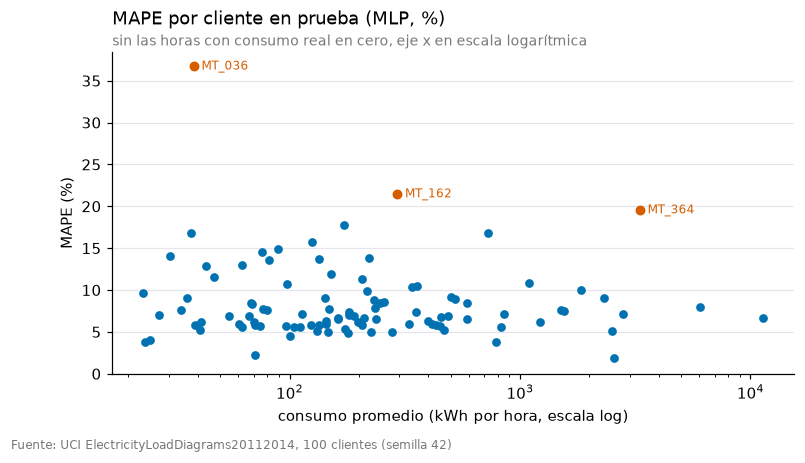


Cliente MT_347 (fuera del panel), consumo promedio 1.15 kWh por hora, horas en cero 1731 de 2184
Seasonal naive de 24 h  MAE 0.341 kWh   MAPE 17.49% (sin contar las horas en cero)


In [11]:
mejor = final.modelo.iloc[0]
pron = pd.read_parquet(R / "pronosticos" / f"{mejor}.parquet")
pron["ape"] = (pron.y - pron.y_hat).abs() / pron.y.abs()
print(f"Horas con consumo real igual a cero en prueba {(pron.y == 0).sum()} de {len(pron)}")
print(f"MAPE con todas las horas {pron.ape.mean():.4f}")
# Las horas en cero se dejan fuera, igual que en src/metrics.py
pron.loc[pron.y == 0, "ape"] = np.nan
por_cliente = pron.groupby("unique_id").agg(mape=("ape", "mean"), consumo=("y", "mean"), y_min=("y", "min"),
                                            horas_cero=("y", lambda v: int((v == 0).sum())))
print(f"MAPE sin las horas en cero {pron.ape.mean():.4f}   mediana del MAPE por cliente {por_cliente.mape.median():.4f}")
print("Los 5 clientes con MAPE más alto")
print(por_cliente.sort_values("mape", ascending=False).head(5).round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(por_cliente.consumo, 100 * por_cliente.mape, color=AZUL, s=22)
peores = por_cliente.sort_values("mape").tail(3)
ax.scatter(peores.consumo, 100 * peores.mape, color=NARANJA, s=30)
for uid, f in peores.iterrows():
    ax.text(f.consumo * 1.08, 100 * f.mape, uid, color=NARANJA, fontsize=8, va="center")
ax.set_xscale("log")
ax.set_ylim(bottom=0)
estilo(ax, f"MAPE por cliente en prueba ({mejor}, %)", "sin las horas con consumo real en cero, eje x en escala logarítmica", "consumo promedio (kWh por hora, escala log)", "MAPE (%)")
pie(fig)
guardar(fig, "3_mape_por_cliente")
plt.show()

# Ejemplo con un cliente fuera del panel que tiene horas casi en cero
from src.data import cargar_horario_todos
h = cargar_horario_todos().loc[C.INICIO_TEST:C.FIN_TEST]
chico = h.mean().loc[lambda s: s > 0].idxmin()
serie = h[chico]
ingenuo = serie.shift(24).dropna()
real = serie.loc[ingenuo.index]
ok = real > 0
print(f"\nCliente {chico} (fuera del panel), consumo promedio {serie.mean():.2f} kWh por hora, "
      f"horas en cero {(real == 0).sum()} de {len(real)}")
print(f"Seasonal naive de 24 h  MAE {(real - ingenuo).abs().mean():.3f} kWh   "
      f"MAPE {((real - ingenuo).abs() / real)[ok].mean():.2%} (sin contar las horas en cero)")

El MAPE es la métrica que peor se porta en este problema. En prueba hay 209 horas con consumo real igual a cero, de 220,800, y con ellas el MAPE del panel sale infinito. Por eso `src/metrics.py` las deja fuera, y así el MLP tiene MAPE de 8.5 %. Pero eso ya es otra métrica, porque justo las horas más difíciles quedan sin contar.

El cliente con más MAPE, MT_036, consume en promedio 38 kWh por hora y llega a 36.7 %. Su error en kWh es pequeño, pero al dividir entre un consumo bajo el porcentaje se vuelve grande. Pasa lo mismo en el ejemplo del cliente MT_347, que no está en el panel. Consume 1.15 kWh por hora y pasa 1,731 de 2,184 horas en cero. El seasonal naive se equivoca solo 0.34 kWh por hora, pero su MAPE es 17.5 % aun dejando fuera las horas en cero, y con ellas no se puede calcular. Entonces el MAPE castiga de más a los clientes chicos y no se define cuando hay ceros. El WAPE (6.6 %) y el MASE no tienen ese problema y son los que se usan para comparar.

### 5.1 Estrategias multi-paso con la LSTM

Las tres estrategias usan la misma configuración que ganó en la LSTM multi-salida (mismo L, estado oculto, capas, dropout, learning rate y normalización).

- Autorregresiva. La LSTM predice una hora y esa predicción entra como valor de la siguiente hora, 24 veces. En entrenamiento usa teacher forcing, o sea recibe los valores reales en vez de sus predicciones.
- Multi-salida. Una capa densa devuelve las 24 horas de una vez a partir del último estado oculto.
- Encoder-decoder. El seq2seq con el calendario de cada hora en el decoder. Se probó con teacher forcing en 0, 0.5 y 1 (probabilidad por lote de usar los valores reales en el decoder) y se eligió con validación.

Variantes de teacher forcing del seq2seq (validación)
      id  tf  epochs  MASE_val
s2s_base 0.5      33    0.9919
 s2s_tf0 0.0      60    0.8876
 s2s_tf1 1.0      59    0.9185


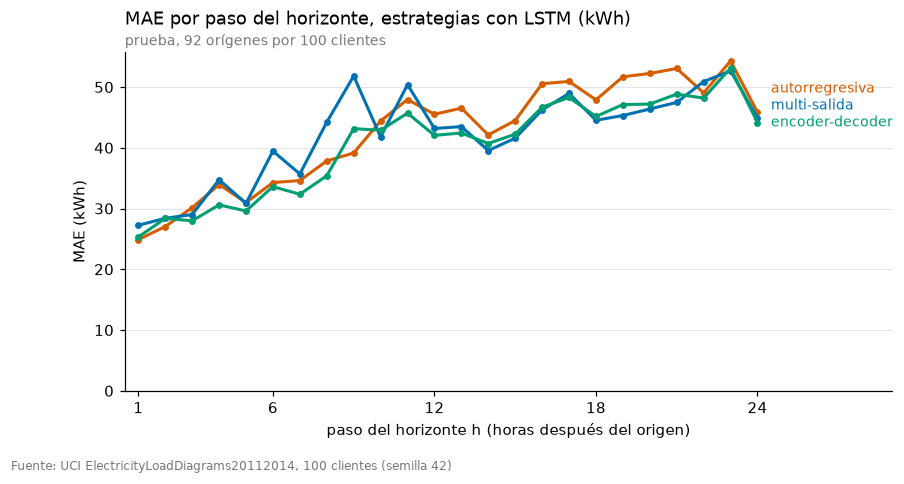

         MAE h=1  MAE h=24  MAE total   MASE
LSTM_AR   24.886    45.855     42.475  0.909
LSTM      27.238    44.934     42.033  0.896
Seq2seq   25.316    44.150     40.464  0.866


In [12]:
print("Variantes de teacher forcing del seq2seq (validación)")
print(tabla[tabla.modelo == "seq2seq"][["id", "tf", "epochs", "MASE_val"]].round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
estrategias = [("LSTM_AR", NARANJA, "autorregresiva"), ("LSTM", AZUL, "multi-salida"), ("Seq2seq", VERDE, "encoder-decoder")]
for n, color, nombre in estrategias:
    ax.plot(range(1, 25), met[n]["mae_por_h"], "o-", color=color, lw=2, ms=3.5)
ax.set_xlim(0.5, 29)
ax.set_xticks([1, 6, 12, 18, 24])
ax.set_ylim(bottom=0)
etiquetas_finales(ax, [24.5] * 3, [met[n]["mae_por_h"][-1] for n, _, _ in estrategias],
                  [e[2] for e in estrategias], [e[1] for e in estrategias], fontsize=9)
estilo(ax, "MAE por paso del horizonte, estrategias con LSTM (kWh)", "prueba, 92 orígenes por 100 clientes",
       "paso del horizonte h (horas después del origen)", "MAE (kWh)")
pie(fig)
guardar(fig, "3_estrategias_multipaso")
plt.show()

print(pd.DataFrame({n: {"MAE h=1": met[n]["mae_por_h"][0], "MAE h=24": met[n]["mae_por_h"][-1],
                        "MAE total": met[n]["MAE"], "MASE": met[n]["MASE"]} for n in ["LSTM_AR", "LSTM", "Seq2seq"]}).T.round(3))

La estrategia autorregresiva es la mejor en la primera hora (MAE 24.9 kWh contra 27.2 de la multi-salida), porque predice un solo paso con toda la información reciente. Pero desde la hora 15 su error queda casi siempre por encima de las otras dos, porque cada predicción entra como dato del paso siguiente y los errores se van sumando. Por eso cierra con el peor MASE de las tres (0.909). La multi-salida tiene picos raros en los pasos 9 y 11 (MAE de 52 y 50), o sea a las 8:00 y a las 10:00, justo cuando sube el consumo de la mañana. Saca las 24 horas con una sola capa densa y le cuesta ubicar bien el momento del salto. El encoder-decoder es el más parejo en todo el horizonte y gana en el total (MAE 40.5 y MASE 0.866). Su decoder avanza hora por hora como la autorregresiva, pero se entrenó con teacher forcing en 0, entonces ya aprendió a trabajar con sus propias predicciones. La autorregresiva se entrenó siempre con los valores reales y en el pronóstico ve por primera vez sus propios errores.

El teacher forcing cambió bastante el resultado del seq2seq. Con 0, o sea entrenando siempre con sus propias predicciones, tuvo el mejor MASE de validación (0.888). Con 1 llegó a 0.919, y con 0.5 se detuvo en el epoch 33 con 0.992. Con teacher forcing en 0 el modelo entrena igual que como se usa en el pronóstico, entonces aprende a corregir sus propios errores. Con 0.5 cada lote cambia de modo al azar y la validación salta mucho entre epochs.

### Error por paso del horizonte y en Navidad

Como todos los orígenes son a las 00:00, el paso h siempre pronostica la hora h − 1 del día. Entonces el error por paso del horizonte y el error por hora del día son la misma curva, y basta con una gráfica.

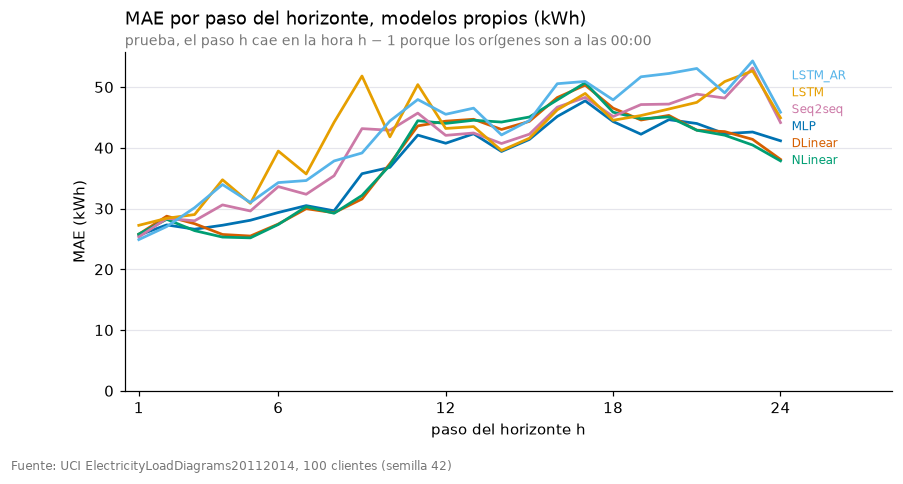

,MASE prueba,MASE 22 al 28 dic,MAE 22 al 28 dic,veces peor en Navidad,MASE prueba sin 22 al 28 dic,MASE validación
MLP,0.819,1.466,81.505,1.790,0.766,0.804
DLinear,0.861,1.863,96.830,2.162,0.779,0.835
NLinear,0.864,1.855,96.412,2.146,0.783,0.837
Seq2seq,0.866,1.385,82.945,1.600,0.823,0.888
LSTM,0.896,1.414,81.122,1.578,0.854,0.912
LSTM_AR,0.909,1.427,83.095,1.571,0.866,0.935


In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = final.modelo.tolist()
colores = CUALITATIVA[:len(orden)]
for n, color in zip(orden, colores):
    ax.plot(range(1, 25), met[n]["mae_por_h"], color=color, lw=1.8)
ax.set_xlim(0.5, 28)
ax.set_xticks([1, 6, 12, 18, 24])
ax.set_ylim(bottom=0)
etiquetas_finales(ax, [24.4] * len(orden), [met[n]["mae_por_h"][-1] for n in orden], orden, colores)
estilo(ax, "MAE por paso del horizonte, modelos propios (kWh)",
       "prueba, el paso h cae en la hora h − 1 porque los orígenes son a las 00:00",
       "paso del horizonte h", "MAE (kWh)")
pie(fig)
guardar(fig, "3_error_por_h")
plt.show()

nav = pd.DataFrame({n: {"MASE prueba": met[n]["MASE"], "MASE 22 al 28 dic": met[n]["MASE_navidad"],
                        "MAE 22 al 28 dic": met[n]["MAE_navidad"]} for n in orden}).T
nav["veces peor en Navidad"] = nav["MASE 22 al 28 dic"] / nav["MASE prueba"]
# MASE de prueba sin la semana de Navidad, para compararlo con el de validación
escalas = pd.Series(E.datos().escalas, index=E.datos().ids)
for n in orden:
    p = pd.read_parquet(R / "pronosticos" / f"{n}.parquet")
    se = (p.y - p.y_hat).abs() / p.unique_id.map(escalas)
    fuera = ~p.ds.between(*C.NAVIDAD)
    nav.loc[n, "MASE prueba sin 22 al 28 dic"] = se[fuera].mean()
    nav.loc[n, "MASE validación"] = met[n]["MASE_val"]
nav.round(3)

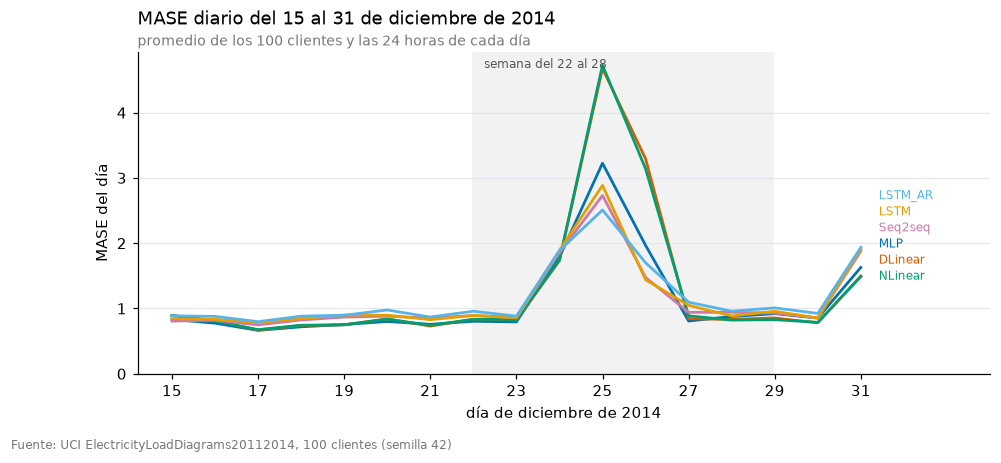

In [14]:
# Error diario de la semana de Navidad para ver qué día falla cada modelo
import matplotlib.dates as mdates
fig, ax = plt.subplots(figsize=(10, 3.8))
finales_dia = []
for i, n in enumerate(orden):
    p = pd.read_parquet(R / "pronosticos" / f"{n}.parquet")
    p = p[(p.ds >= "2014-12-15") & (p.ds <= "2014-12-31 23:00")]
    esc = E.datos().escalas
    escalas = pd.Series(esc, index=E.datos().ids)
    p["se"] = (p.y - p.y_hat).abs() / p.unique_id.map(escalas)
    d = p.groupby(p.ds.dt.date).se.mean()
    ax.plot(pd.to_datetime(d.index), d.values, color=CUALITATIVA[i], lw=1.8)
    finales_dia.append(d.values[-1])
ax.axvspan(pd.Timestamp("2014-12-22"), pd.Timestamp("2014-12-28 23:00"), color="#F2F2F2", zorder=0)
ax.text(pd.Timestamp("2014-12-22 06:00"), ax.get_ylim()[1] * 0.95, "semana del 22 al 28", color="#555555", fontsize=8)
ax.set_xlim(right=pd.Timestamp("2015-01-03"))
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.DayLocator(range(15, 32, 2)))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
etiquetas_finales(ax, [mdates.date2num(pd.Timestamp("2014-12-31 10:00"))] * len(orden), finales_dia, orden, colores)
estilo(ax, "MASE diario del 15 al 31 de diciembre de 2014", "promedio de los 100 clientes y las 24 horas de cada día",
       "día de diciembre de 2014", "MASE del día")
pie(fig)
guardar(fig, "3_navidad_diario")
plt.show()

Del 22 al 28 de diciembre todos los modelos empeoran, pero no igual. Fuera de esa semana los 6 modelos están entre 0.77 y 0.87, y dentro de ella la diferencia crece. Los lineales pasan de MASE 0.86 a 1.86, o sea más del doble. El MLP sube a 1.47 y las tres recurrentes a entre 1.39 y 1.43. En la gráfica diaria el día 25 es el peor para todos, con MASE de 4.7 en DLinear y NLinear, 3.2 en el MLP y entre 2.5 y 2.9 en las recurrentes. El día 26 los lineales siguen mal (3.2 a 3.3) y los demás bajan a entre 1.4 y 1.9.

La diferencia sale de las covariables. DLinear y NLinear solo ven la ventana de consumo, entonces el 25 pronostican un jueves normal. Y el 26 la ventana ya incluye el 25, que parece un día raro, y eso también los confunde. El MLP y las recurrentes reciben la marca de feriado y por eso bajan su pronóstico ese día, aunque no lo suficiente. El 24 y el 31 todos suben a cerca de 1.8. Esos días no son feriado oficial en Portugal, entonces ningún modelo los marca, pero el consumo baja un poco y cambia de forma durante el día.

En la tabla de errores por cliente, MT_279 tiene un MAE de 807 kWh, pero su MASE (1.10) es parecido al de clientes mucho más chicos. Es el cliente más grande del panel, con unos 11,480 kWh por hora. Por eso el MAE y el RMSE del panel los ponen pocos clientes grandes y el MASE sirve mejor para ver dónde falla el modelo.

In [15]:
print("MAE y RMSE por cliente del mejor modelo propio, los 5 con más error y los 5 con menos")
pc = pd.DataFrame({"MAE": met[mejor]["mae_por_cliente"], "RMSE": met[mejor]["rmse_por_cliente"],
                   "MASE": met[mejor]["mase_por_cliente"]})
pd.concat([pc.sort_values("MASE").tail(5), pc.sort_values("MASE").head(5)]).round(3)

MAE y RMSE por cliente del mejor modelo propio, los 5 con más error y los 5 con menos


,MAE,RMSE,MASE
MT_338,20.803,40.638,1.094
MT_279,807.282,1567.981,1.097
MT_209,36.974,52.579,1.130
MT_334,8.378,15.252,1.153
MT_174,9.917,20.908,1.156
MT_356,2.611,3.807,0.140
MT_368,15.642,22.813,0.368
MT_369,30.456,42.264,0.423
MT_097,20.774,30.994,0.457
MT_013,8.963,14.334,0.493


### MASE con H = 168

Para los tres modelos más baratos (DLinear, NLinear y MLP) se entrenó también una versión con H = 168, una semana completa, con la misma configuración ganadora. En prueba se usan los 86 orígenes cuyo objetivo de 168 horas cae completo antes del 2014-12-31.

In [16]:
pd.DataFrame({n: {"MASE H=24": met[n]["MASE"], "MASE H=168": met[n].get("MASE_h168"),
                  "orígenes H=168": met[n].get("n_origenes_h168")} for n in ["DLinear", "NLinear", "MLP"]}).T.round(4)

,MASE H=24,MASE H=168,orígenes H=168
DLinear,0.8614,0.9872,86.0
NLinear,0.8641,0.9854,86.0
MLP,0.8194,1.0009,86.0


Con H = 168 los tres modelos quedan en MASE cercano a 1 (DLinear 0.987, NLinear 0.985 y el MLP 1.001). La escala del MASE es la misma que con H = 24, el error del seasonal naive de un día dentro de entrenamiento. Entonces pronosticar una semana completa se equivoca más o menos lo mismo que copiar el día anterior, y bastante más que pronosticar solo un día (0.82 a 0.86). Con H = 168 el orden se invierte y los lineales quedan un poco por delante del MLP. Con un horizonte largo lo que más ayuda es repetir el patrón semanal, y eso los lineales lo hacen bien con pocos parámetros. El MLP saca las 168 salidas con más parámetros y le cuesta más generalizar.

### Reentrenamiento mensual

El mejor modelo propio, elegido por MASE de validación, se volvió a entrenar al inicio de cada mes de prueba (1 de octubre, 1 de noviembre y 1 de diciembre) con todos los datos disponibles hasta ese día, o sea con ventana expandible. Como ya no queda un bloque de validación limpio, se entrena con el mismo número de epochs que eligió el early stopping original. El z-score también se recalcula con toda la historia disponible en cada reentrenamiento.

In [17]:
re = json.loads(next((R / "reentreno").glob("*.json")).read_text())
print("Modelo", re["modelo"], "  epochs por reentrenamiento", re["epochs"])
print(pd.DataFrame({"pesos fijos hasta 2014-09-30": re["fijo"], "reentrenado cada mes": re["reentreno_mensual"]}).T.round(4))
print(pd.DataFrame(re["entrenamientos"]).round(1).to_string(index=False))

Modelo MLP   epochs por reentrenamiento 10
                                  MAE      RMSE    WAPE    MASE  MASE_navidad
pesos fijos hasta 2014-09-30  37.3688  183.2819  0.0662  0.8194        1.4664
reentrenado cada mes          37.7750  183.6120  0.0669  0.8280        1.4410
              hasta  t_s
2014-09-30 23:00:00  4.4
2014-10-31 23:00:00  4.3
2014-11-30 23:00:00  4.4


Reentrenar cada mes no mejoró al MLP. Con los pesos fijos tiene MASE 0.819 y reentrenado cada mes 0.828. Solo mejora un poco en Navidad (1.441 contra 1.466), porque el reentreno del 1 de diciembre ya incluye noviembre. La diferencia en el total (0.009) es del mismo tamaño que la que dan las semillas (desviación de 0.008), o sea no se puede decir que uno sea mejor que el otro. Cada reentrenamiento tarda unos 4 segundos, entonces con un modelo así de barato se podría reentrenar seguido sin problema. Pero en este caso los pesos de septiembre ya capturan bien el patrón y uno o dos meses más de datos no cambian mucho. Hay que notar que el reentreno usa 10 epochs fijos sin early stopping, porque ya no queda validación limpia, y eso puede costar un poco de precisión.

### 5.3 Modelo local contra global

El mejor modelo propio se entrenó de dos formas. El global es el de arriba, un solo modelo para los 100 clientes. El local es un modelo por cliente para 10 clientes elegidos con semilla 42, cada uno entrenado solo con las ventanas de su serie y con la misma configuración. Se compara el MASE de prueba en esos 10 clientes.

In [18]:
lg = json.loads((R / "local_global.json").read_text())
comp = pd.DataFrame({"MASE local": lg["mase_por_cliente_local"], "MASE global": lg["mase_por_cliente_global"]})
comp["mejora del global (%)"] = 100 * (1 - comp["MASE global"] / comp["MASE local"])
consumo = cargar_panel().query("ds <= @C.FIN_TRAIN").groupby("unique_id").y.mean()
comp["consumo promedio (kWh)"] = consumo.reindex(comp.index)
print(f"Modelo {lg['modelo']}   MASE local {lg['MASE_local']:.4f}   MASE global {lg['MASE_global']:.4f}   "
      f"entrenar los 10 locales {lg['t_entrenamiento_local_total_s']:.0f} s")
comp = comp.sort_values("mejora del global (%)")
comp.round(3)

Modelo MLP   MASE local 0.8239   MASE global 0.8141   entrenar los 10 locales 18 s


,MASE local,MASE global,mejora del global (%),consumo promedio (kWh)
MT_279,0.958,1.097,-14.509,11479.718
MT_097,0.438,0.457,-4.451,190.511
MT_050,0.722,0.735,-1.750,164.507
MT_046,0.828,0.835,-0.864,131.096
MT_320,0.782,0.766,2.037,101.882
MT_245,1.003,0.972,3.061,192.434
MT_183,0.881,0.849,3.597,84.732
MT_267,0.781,0.737,5.598,68.324
MT_363,1.022,0.938,8.189,2523.440
MT_359,0.824,0.754,8.567,107.605


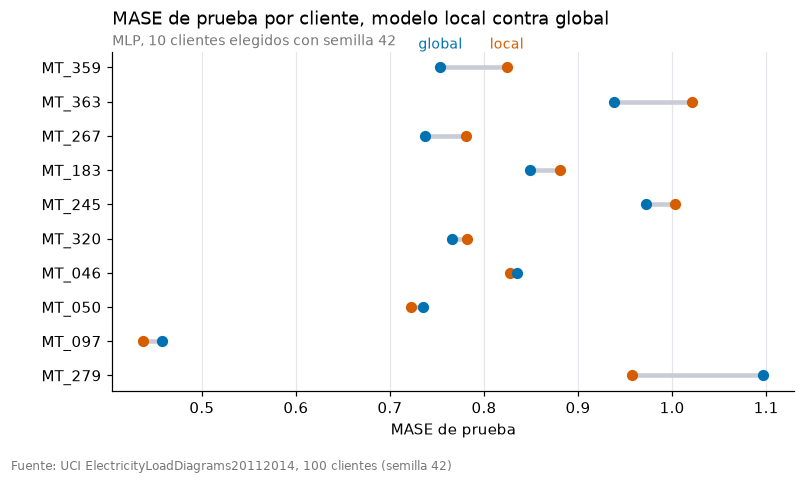

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(comp))
ax.hlines(y, comp["MASE global"], comp["MASE local"], color=GRIS_CLARO, lw=3)
ax.scatter(comp["MASE local"], y, color=NARANJA, s=40, zorder=3)
ax.scatter(comp["MASE global"], y, color=AZUL, s=40, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(comp.index)
ax.text(comp["MASE local"].iloc[-1], len(comp) - 0.45, "local", color=NARANJA, ha="center", fontsize=9)
ax.text(comp["MASE global"].iloc[-1], len(comp) - 0.45, "global", color=AZUL, ha="center", fontsize=9)
estilo(ax, "MASE de prueba por cliente, modelo local contra global", f"{lg['modelo']}, 10 clientes elegidos con semilla 42",
       "MASE de prueba")
ax.yaxis.grid(False)
ax.xaxis.grid(True, color="#E5E5EC")
pie(fig)
guardar(fig, "3_local_vs_global")
plt.show()

En los 10 clientes el modelo global tiene MASE 0.814 y los locales 0.824, o sea el global es un poco mejor, cerca de 1 % en promedio. El global gana en 6 de los 10 clientes, con mejoras de hasta 8.6 % en MT_359. Cada modelo local tiene solo unas 21,700 ventanas de su cliente, mientras el global aprende de 2.17 millones de ventanas de 100 clientes, y los patrones de día y semana se parecen mucho entre clientes.

El caso más grande a favor del local es MT_279, el cliente más grande del panel. Ahí el local tiene MASE 0.958 y el global 1.097. Su forma de consumo es distinta a la mayoría y el global la promedia con los demás. Por ese cliente el MAE en kWh de los 10 clientes sale mejor para los locales (96.0 contra 104.8), aunque el MASE diga lo contrario. Entrenar los 10 modelos locales tomó 18 segundos, pero para los 100 clientes serían 100 modelos que guardar y mantener. Entonces conviene el global, y para clientes muy distintos como MT_279 se podría agregar un modelo propio.

### Sensibilidad a la semilla

El mejor modelo propio se repitió con 3 semillas (42, 7 y 123). La semilla cambia la inicialización de los pesos y el orden en que se muestrean las ventanas.

In [20]:
sem = json.loads((R / "semillas.json").read_text())
print("Modelo", sem["modelo"], " iteración", sem["id_iteracion"])
print(pd.DataFrame(sem["corridas"]).round(4).to_string(index=False))
print(f"\nMASE de prueba {sem['MASE_prueba_media']:.4f} ± {sem['MASE_prueba_desv']:.4f} (desviación estándar)")
print(f"MASE de validación {sem['MASE_val_media']:.4f} ± {sem['MASE_val_desv']:.4f}")

Modelo MLP  iteración mlp_revin
 semilla  MASE_val  MASE_prueba  MAE_prueba  WAPE_prueba
      42    0.8041       0.8194     37.3688       0.0662
       7    0.7992       0.8098     37.1474       0.0658
     123    0.8091       0.8249     37.7190       0.0668

MASE de prueba 0.8181 ± 0.0077 (desviación estándar)
MASE de validación 0.8041 ± 0.0050


Con tres semillas el MLP tiene MASE de prueba de 0.818 con desviación estándar de 0.008 (de 0.810 a 0.825). En validación la desviación es de 0.005. Esto sirve como regla para leer las tablas. Las diferencias menores a unos 0.01 de MASE pueden ser solo ruido de la semilla. Entonces el empate entre DLinear (0.861), NLinear (0.864) y el seq2seq (0.866) no se puede romper con estos datos. Pero la ventaja del MLP sobre DLinear (0.04) y la de DLinear sobre la LSTM autorregresiva (0.05) son unas 5 veces la desviación y sí parecen reales. La semilla 7 tuvo mejor validación (0.799) y también mejor prueba (0.810), así que el orden de las semillas en validación se mantuvo en prueba.

### Archivos que deja este notebook

- `Resultados/pronosticos/<modelo>.parquet` con `unique_id, ds, modelo, origen, h, y, y_hat` para MLP, DLinear, NLinear, LSTM, LSTM_AR y Seq2seq.
- `Resultados/metricas/<modelo>.json` con las métricas de prueba y los datos de la tabla comparativa.
- `Resultados/iteraciones/*.json` con la configuración, las curvas por epoch, los parámetros, los tiempos y la memoria de cada iteración.
- `Resultados/historia/`, `Resultados/reentreno/`, `Resultados/local_global.json` y `Resultados/semillas.json`.